In [2]:
import os
import zipfile
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout, BatchNormalization
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
zip_path = '/content/drive/MyDrive/shipsnet.zip'
extract_path = '/content/shipsnet_extracted'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("تم فك ضغط الملف بنجاح في المسار:", extract_path)
    print("محتويات المجلد:", os.listdir(extract_path))
else:
    print("خطأ: لم يتم العثور على ملف shipsnet.zip في المسار المحدد. يرجى التأكد من مكانه في الدرايف.")

تم فك ضغط الملف بنجاح في المسار: /content/shipsnet_extracted
محتويات المجلد: ['shipsnet']


In [5]:
import glob

images_dir = os.path.join(extract_path, 'shipsnet')

if not os.path.exists(images_dir):
    images_dir = extract_path

image_paths = glob.glob(os.path.join(images_dir, '*.png')) + glob.glob(os.path.join(images_dir, '**/*.png'), recursive=True)

print(f"تم العثور على {len(image_paths)} صورة.")

X_list = []
y_list = []

for path in image_paths:
    img = cv2.imread(path)
    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (80, 80))

        filename = os.path.basename(path)
        if filename.startswith('1__'):
            label = 1
        elif filename.startswith('0__'):
            label = 0
        else:
            continue

        X_list.append(img)
        y_list.append(label)

X = np.array(X_list).astype('float32') / 255.0
y = np.array(y_list).astype('int32')

print("\n--- تم تحميل البيانات بنجاح ---")
print("شكل مصفوفة الصور (X shape):", X.shape)
print("شكل مصفوفة التصنيفات (y shape):", y.shape)
print("توزيع العينات (0: No-Ship, 1: Ship):", np.bincount(y))

تم العثور على 4000 صورة.

--- تم تحميل البيانات بنجاح ---
شكل مصفوفة الصور (X shape): (4000, 80, 80, 3)
شكل مصفوفة التصنيفات (y shape): (4000,)
توزيع العينات (0: No-Ship, 1: Ship): [3000 1000]


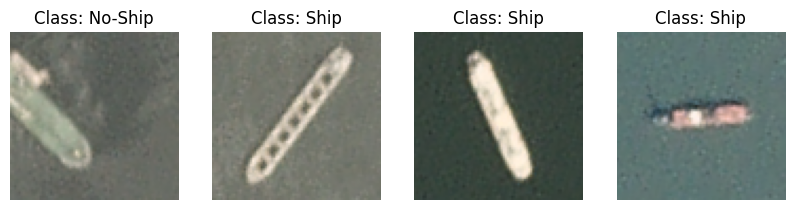

In [ ]:
import random

plt.figure(figsize=(10, 5))
for i in range(4):
    idx = random.randint(0, len(X) - 1)
    plt.subplot(1, 4, i + 1)
    plt.imshow(X[idx])
    plt.title("Class: " + ("Ship" if y[idx] == 1 else "No-Ship"))
    plt.axis('off')
plt.show()

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"حجم بيانات التدريب (Train): {X_train.shape} | التصنيفات: {np.bincount(y_train)}")
print(f"حجم بيانات التحقق (Val):  {X_val.shape} | التصنيفات: {np.bincount(y_val)}")
print(f"حجم بيانات الفحص (Test): {X_test.shape} | التصنيفات: {np.bincount(y_test)}")

حجم بيانات التدريب (Train): (3200, 80, 80, 3) | التصنيفات: [2400  800]
حجم بيانات التحقق (Val):  (400, 80, 80, 3) | التصنيفات: [300 100]
حجم بيانات الفحص (Test): (400, 80, 80, 3) | التصنيفات: [300 100]


In [ ]:
train_datagen = ImageDataGenerator(
    rotation_range=30,
    horizontal_flip=True,
    vertical_flip=True,
    brightness_range=[0.8, 1.2]
)

train_generator = train_datagen.flow(X_train, y_train, batch_size=32)

In [ ]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(80, 80, 3)),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(128, (3, 3), activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.4),

    Flatten(),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 78, 78, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 78, 78, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 39, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 39, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 37, 37, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 37, 37, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       524,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 618,817 (2.36 MB)

 Trainable params: 618,241 (2.36 MB)

 Non-trainable params: 576 (2.25 KB)

In [ ]:
history = model.fit(
    train_generator,
    epochs=20,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 20s 90ms/step - accuracy: 0.6587 - loss: 0.7887 - precision: 0.2978 - recall: 0.2688 - val_accuracy: 0.7500 - val_loss: 0.5606 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 77ms/step - accuracy: 0.7275 - loss: 0.6524 - precision: 0.3854 - recall: 0.1513 - val_accuracy: 0.7500 - val_loss: 0.5674 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 86ms/step - accuracy: 0.7456 - loss: 0.6243 - precision: 0.4676 - recall: 0.1262 - val_accuracy: 0.7500 - val_loss: 0.5587 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 72ms/step - accuracy: 0.7437 - loss: 0.6211 - precision: 0.4495 - recall: 0.1112 - val_accuracy: 0.7500 - val_loss: 0.7013 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 85ms/step - accuracy: 0.7484 - loss: 0.5996 - precision: 0.4885 - recall: 0.1325

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = {0: class_weights[0], 1: class_weights[1]}
print("الأوزان المحسوبة (Class Weights):", class_weight_dict)

الأوزان المحسوبة (Class Weights): {0: np.float64(0.6666666666666666), 1: np.float64(2.0)}


In [ ]:
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy', tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')])

history = model.fit(
    train_generator,
    epochs=25,
    validation_data=(X_val, y_val),
    class_weight=class_weight_dict,
    verbose=1
)

Epoch 1/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 18s 81ms/step - accuracy: 0.7597 - loss: 0.7323 - precision: 0.5928 - recall: 0.1238 - val_accuracy: 0.7500 - val_loss: 0.7775 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 86ms/step - accuracy: 0.7625 - loss: 0.6742 - precision: 0.5758 - recall: 0.1900 - val_accuracy: 0.7650 - val_loss: 0.4817 - val_precision: 1.0000 - val_recall: 0.0600
Epoch 3/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 70ms/step - accuracy: 0.7553 - loss: 0.6657 - precision: 0.5241 - recall: 0.2313 - val_accuracy: 0.7550 - val_loss: 0.4851 - val_precision: 1.0000 - val_recall: 0.0200
Epoch 4/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 9s 92ms/step - accuracy: 0.7472 - loss: 0.6627 - precision: 0.4889 - recall: 0.2475 - val_accuracy: 0.7525 - val_loss: 0.5111 - val_precision: 1.0000 - val_recall: 0.0100
Epoch 5/25
100/100 ━━━━━━━━━━━━━━━━━━━━ 8s 84ms/step - accuracy: 0.6922 - loss: 0.6517 - precision: 0.3596 - recall: 0.2962 - val_accuracy: 0.7525 

In [ ]:
train_datagen_tuned = ImageDataGenerator(
    horizontal_flip=True,
    vertical_flip=True
)
train_generator_tuned = train_datagen_tuned.flow(X_train, y_train, batch_size=32)

In [ ]:
model_tuned = Sequential([
    Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(80, 80, 3)),
    BatchNormalization(),
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.25),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D((2, 2)),
    Dropout(0.3),

    Flatten(),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

opt = tf.keras.optimizers.Adam(learning_rate=0.0001)

model_tuned.compile(
    optimizer=opt,
    loss='binary_crossentropy',
    metrics=['accuracy',
             tf.keras.metrics.Precision(name='precision'),
             tf.keras.metrics.Recall(name='recall'),
             tf.keras.metrics.AUC(name='auc')]
)

model_tuned.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 80, 80, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 80, 80, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 80, 80, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 80, 80, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 40, 40, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 40, 40, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 40, 40, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 40, 40, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 40, 40, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 40, 40, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 20, 20, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25600)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,276,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,343,905 (12.76 MB)

 Trainable params: 3,343,265 (12.75 MB)

 Non-trainable params: 640 (2.50 KB)

In [ ]:
history_tuned = model_tuned.fit(
    train_generator_tuned,
    epochs=20,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 17s 57ms/step - accuracy: 0.7928 - auc: 0.9133 - loss: 0.5147 - precision: 0.5527 - recall: 0.8975 - val_accuracy: 0.7500 - val_auc: 0.7574 - val_loss: 0.7458 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.8828 - auc: 0.9575 - loss: 0.3198 - precision: 0.7045 - recall: 0.9150 - val_accuracy: 0.7500 - val_auc: 0.6987 - val_loss: 1.2238 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9128 - auc: 0.9692 - loss: 0.2574 - precision: 0.7677 - recall: 0.9337 - val_accuracy: 0.7375 - val_auc: 0.6955 - val_loss: 1.0692 - val_precision: 0.4242 - val_recall: 0.1400
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - accuracy: 0.9331 - auc: 0.9773 - loss: 0.2176 - precision: 0.8330 - recall: 0.9162 - val_accuracy: 0.7300 - val_auc: 0.8171 - val_loss: 0.7032 - val_precision: 0.4706 - val_recall: 0.6400
Epoch 5/20


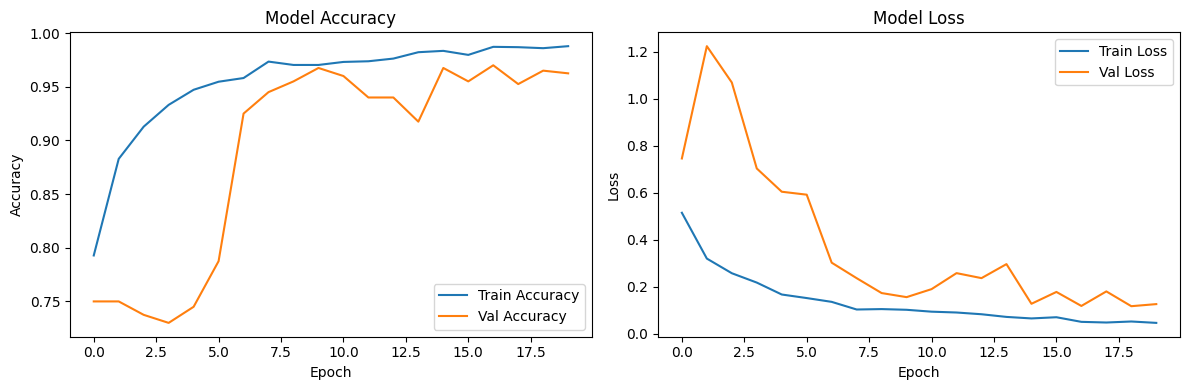

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_tuned.history['accuracy'], label='Train Accuracy')
plt.plot(history_tuned.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_tuned.history['loss'], label='Train Loss')
plt.plot(history_tuned.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 100ms/step

--- Classification Report on Test Set ---
              precision    recall  f1-score   support

     No-Ship       1.00      0.97      0.98       300
        Ship       0.92      0.99      0.95       100

    accuracy                           0.97       400
   macro avg       0.96      0.98      0.97       400
weighted avg       0.98      0.97      0.98       400



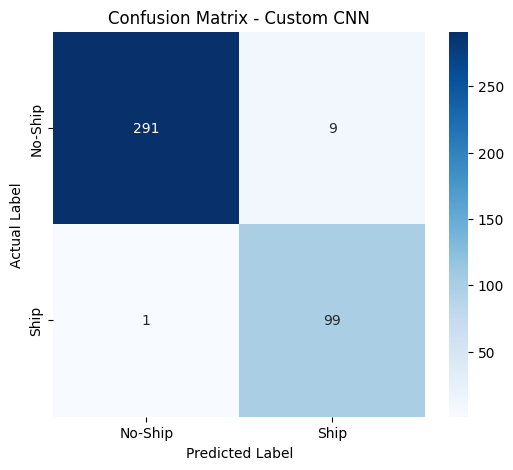

In [ ]:
import seaborn as sns

y_pred_probs = model_tuned.predict(X_test)
y_pred = (y_pred_probs > 0.5).astype("int32")

print("\n--- Classification Report on Test Set ---")
print(classification_report(y_test, y_pred, target_names=['No-Ship', 'Ship']))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No-Ship', 'Ship'],
            yticklabels=['No-Ship', 'Ship'])
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.title('Confusion Matrix - Custom CNN')
plt.show()

In [ ]:
!pip install ultralytics

from ultralytics import YOLO
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("YOLOv8 Environment Ready!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 28.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
YOLOv8 Environment Ready!


In [ ]:
def detect_ships_in_full_scene(scene_img_path, cnn_model, window_size=80, step_size=40, confidence_threshold=0.85):
    large_img = cv2.imread(scene_img_path)
    if large_img is None:
        print("خطأ: لم يتم العثور على صورة المشهد الكبير.")
        return

    large_img_rgb = cv2.cvtColor(large_img, cv2.COLOR_BGR2RGB)
    display_img = large_img_rgb.copy()

    h, w, _ = large_img_rgb.shape
    detected_boxes = []

    import time
    start_time = time.time()

    for y in range(0, h - window_size + 1, step_size):
        for x in range(0, w - window_size + 1, step_size):
            crop = large_img_rgb[y:y+window_size, x:x+window_size]

            crop_input = np.expand_dims(crop, axis=0).astype('float32') / 255.0

            pred = cnn_model.predict(crop_input, verbose=0)[0][0]

            if pred >= confidence_threshold:
                detected_boxes.append((x, y, x + window_size, y + window_size, pred))

    end_time = time.time()
    inference_speed = end_time - start_time

    ship_count = 0
    for (x1, y1, x2, y2, score) in detected_boxes:
        cv2.rectangle(display_img, (x1, y1), (x2, y2), (255, 0, 0), 2) # رسم مربع أحمر
        cv2.putText(display_img, f"Ship:{score:.2f}", (x1, y1 - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 0, 0), 1)
        ship_count += 1

    plt.figure(figsize=(10, 10))
    plt.imshow(display_img)
    plt.title(f"Detection Results: Found {ship_count} Ships | Processing Speed: {inference_speed:.4f} sec")
    plt.axis('off')
    plt.show()

    return ship_count, inference_speed

المجلد يحتوي على صور صغيرة فقط، جاري بناء مشهد كامل عشوائي للـ Live Demo...
تم بناء مشهد افتراضي بنجاح وحفظه في: /content/demo_constructed_scene.png


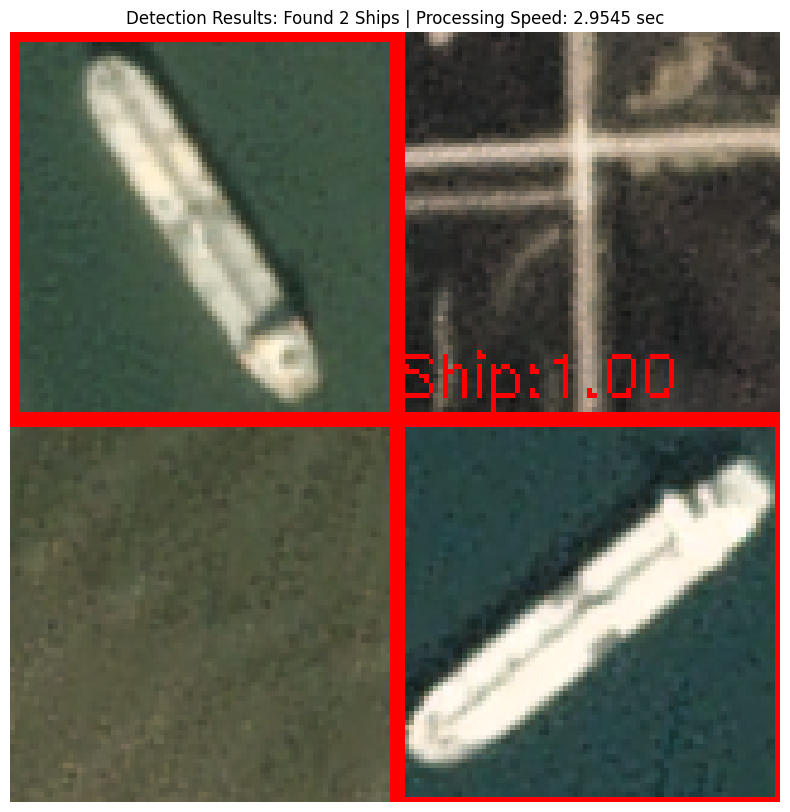

In [ ]:
import glob

actual_dir = '/content/shipsnet_extracted/shipsnet/shipsnet'

all_files = glob.glob(os.path.join(actual_dir, '*.png')) + glob.glob(os.path.join(actual_dir, '*.jpg'))

large_scenes = [p for p in all_files if not os.path.basename(p).startswith('1__') and not os.path.basename(p).startswith('0__')]

if len(large_scenes) > 0:
    sample_scene_path = large_scenes[0]
    print(f"تم العثور على صورة المشهد الكبير تلقائياً في:\n{sample_scene_path}")
else:
    print("المجلد يحتوي على صور صغيرة فقط، جاري بناء مشهد كامل عشوائي للـ Live Demo...")
    sample_images = [p for p in all_files if os.path.basename(p).startswith('1__')][:4]
    sample_no_images = [p for p in all_files if os.path.basename(p).startswith('0__')][:4]

    row1 = np.hstack([cv2.imread(sample_images[0]), cv2.imread(sample_no_images[0])])
    row2 = np.hstack([cv2.imread(sample_no_images[1]), cv2.imread(sample_images[1])])
    grid_scene = np.vstack([row1, row2])

    sample_scene_path = '/content/demo_constructed_scene.png'
    cv2.imwrite(sample_scene_path, grid_scene)
    print(f"تم بناء مشهد افتراضي بنجاح وحفظه في: {sample_scene_path}")

count, speed = detect_ships_in_full_scene(sample_scene_path, model_tuned, window_size=80, step_size=20, confidence_threshold=0.88)

In [ ]:
!find /content/shipsnet_extracted -maxdepth 3 -type d

/content/shipsnet_extracted
/content/shipsnet_extracted/shipsnet
/content/shipsnet_extracted/shipsnet/shipsnet


In [6]:
from skimage.feature import hog
from sklearn.svm import SVC
import numpy as np

print("جاري استخراج ميزات HOG لـ 4000 صورة... يرجى الانتظار")

X_hog_list = []

for img in X:
    img_uint8 = (img * 255).astype(np.uint8)
    gray_img = cv2.cvtColor(img_uint8, cv2.COLOR_RGB2GRAY)

    features = hog(gray_img, orientations=9, pixels_per_cell=(8, 8),
                   cells_per_block=(2, 2), visualize=False)

    X_hog_list.append(features)

X_hog = np.array(X_hog_list)

print("شكل مصفوفة ميزات HOG الجديدة:", X_hog.shape)

جاري استخراج ميزات HOG لـ 4000 صورة... يرجى الانتظار
شكل مصفوفة ميزات HOG الجديدة: (4000, 2916)


In [7]:
X_train_hog, X_test_hog, y_train_hog, y_test_hog = train_test_split(
    X_hog, y, test_size=0.20, random_state=42, stratify=y
)

print(f"بيانات تدريب الـ SVM: {X_train_hog.shape} | بيانات الفحص: {X_test_hog.shape}")

svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_model.fit(X_train_hog, y_train_hog)

print("تم تدريب نموذج HOG + SVM بنجاح!")

بيانات تدريب الـ SVM: (3200, 2916) | بيانات الفحص: (800, 2916)
تم تدريب نموذج HOG + SVM بنجاح!



--- Real Classification Report (HOG + SVM Baseline) ---
              precision    recall  f1-score   support

     No-Ship       0.99      0.99      0.99       600
        Ship       0.98      0.96      0.97       200

    accuracy                           0.99       800
   macro avg       0.99      0.98      0.98       800
weighted avg       0.99      0.99      0.99       800



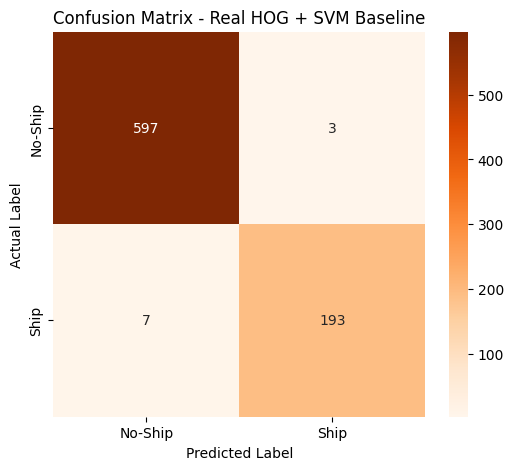

In [8]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

y_pred_svm = svm_model.predict(X_test_hog)

print("\n--- Real Classification Report (HOG + SVM Baseline) ---")
print(classification_report(y_test_hog, y_pred_svm, target_names=['No-Ship', 'Ship']))

cm_svm = confusion_matrix(y_test_hog, y_pred_svm)
plt.figure(figsize=(6, 5))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['No-Ship', 'Ship'],
            yticklabels=['No-Ship', 'Ship'])
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.title('Confusion Matrix - Real HOG + SVM Baseline')
plt.show()